1. Project Introduction
This project focuses on analysing Swiggy food delivery data to understand customer ordering patterns, restaurant performance, food preferences and delivery efficiency.

The analysis uses Python libraries such as Pandas, NumPy, Matplotlib and Seaborn to explore the dataset and identify meaningful business insights.

Project Objectives
- Understand customer ordering behaviour.
- Identify popular restaurants and food categories.
- Analyse delivery performance and customer ratings.
- Identify ordering trends and provide recommendations.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")

In [4]:
df = pd.read_csv("Swiggy Food Delivery Data Analysis.csv")

In [5]:
df.head()

,Order_ID,Customer_ID,City,Restaurant_Name,Food_Category,Order_Date,Order_Time,Order_Value,Delivery_Time,Rating,Payment_Method,Order_Status,Distance_km,Discount,Delivery_Fee
0,SWG100000,CUST37343,Ahmedabad,Punjabi Tadka,North Indian,2025-04-13,18:41,260.47,22.0,4.3,Credit Card,Delivered,2.6,0.00,31.07
1,SWG100001,CUST45683,Bengaluru,Biryani Blues,Biryani,2025-12-15,18:54,1012.15,29.0,3.6,UPI,Delivered,1.3,53.06,16.23
2,SWG100002,CUST43263,Kolkata,Udupi Express,South Indian,2025-09-28,21:07,485.66,58.0,4.0,Credit Card,Delivered,9.0,0.00,49.23
3,SWG100003,CUST42294,Pune,Delhi Darbar,North Indian,2025-04-17,19:29,264.34,90.0,2.9,UPI,Delivered,18.7,62.57,93.53
4,SWG100004,CUST59025,Bengaluru,Big Bite,Burgers,2025-03-13,12:38,819.00,37.0,4.0,Credit Card,Delivered,6.2,0.00,42.31


In [7]:
df.shape

(15000, 15)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         15000 non-null  object 
 1   Customer_ID      15000 non-null  object 
 2   City             15000 non-null  object 
 3   Restaurant_Name  15000 non-null  object 
 4   Food_Category    15000 non-null  object 
 5   Order_Date       15000 non-null  object 
 6   Order_Time       15000 non-null  object 
 7   Order_Value      15000 non-null  float64
 8   Delivery_Time    15000 non-null  float64
 9   Rating           15000 non-null  float64
 10  Payment_Method   15000 non-null  object 
 11  Order_Status     15000 non-null  object 
 12  Distance_km      15000 non-null  float64
 13  Discount         15000 non-null  float64
 14  Delivery_Fee     15000 non-null  float64
dtypes: float64(6), object(9)
memory usage: 1.7+ MB


In [9]:
df.isnull().sum()

Order_ID           0
Customer_ID        0
City               0
Restaurant_Name    0
Food_Category      0
Order_Date         0
Order_Time         0
Order_Value        0
Delivery_Time      0
Rating             0
Payment_Method     0
Order_Status       0
Distance_km        0
Discount           0
Delivery_Fee       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)


## 2. Exploratory Data Analysis (EDA)

### 2.1 Numerical Data Analysis

In this section, we examine the statistical properties of numerical columns to understand order values, delivery times, customer ratings, discounts, delivery distances and delivery fees.


In [11]:
df.describe()

,Order_Value,Delivery_Time,Rating,Distance_km,Discount,Delivery_Fee
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,611.922017,43.233000,3.985740,5.288907,28.290541,41.280385
std,287.721340,15.409794,0.477909,3.141607,45.378103,13.526014
min,109.480000,12.000000,1.700000,0.500000,0.000000,10.000000
25%,399.567500,32.000000,3.700000,3.000000,0.000000,31.827500
50%,558.460000,41.000000,4.000000,4.600000,0.000000,38.985000
75%,766.832500,52.000000,4.300000,6.900000,50.050000,48.572500
max,2280.420000,90.000000,5.000000,20.000000,149.980000,111.350000



### 2.2 Categorical Data Analysis

This section examines the unique values and frequency distributions of categorical variables such as cities, restaurants, food categories, payment methods and order statuses.


In [12]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts().head(10))


Order_ID
Unique values: 15000
Order_ID
SWG100000    1
SWG100001    1
SWG100002    1
SWG100003    1
SWG100004    1
SWG100005    1
SWG100006    1
SWG100007    1
SWG100008    1
SWG100009    1
Name: count, dtype: int64

Customer_ID
Unique values: 12981
Customer_ID
CUST31541    4
CUST15958    4
CUST32616    4
CUST55369    4
CUST10862    4
CUST44001    4
CUST29350    4
CUST41683    4
CUST38663    3
CUST15340    3
Name: count, dtype: int64

City
Unique values: 10
City
Hyderabad    1574
Lucknow      1520
Mumbai       1515
Pune         1512
Ahmedabad    1509
Jaipur       1481
Delhi        1478
Kolkata      1478
Bengaluru    1471
Chennai      1462
Name: count, dtype: int64

Restaurant_Name
Unique values: 40
Restaurant_Name
Punjabi Tadka       634
The Curry House     600
Delhi Darbar        591
Shahi Rasoi         577
Dum Biryani         511
Biryani Hub         499
Hyderabadi House    492
Biryani Blues       484
South Spice         481
Madras Cafe         476
Name: count, dtype: int64

Food_Cate

In [13]:
print("Cities:", df['City'].unique())

print("\nFood Categories:", df['Food_Category'].unique())

print("\nPayment Methods:", df['Payment_Method'].unique())

print("\nOrder Status:", df['Order_Status'].unique())

Cities: ['Ahmedabad' 'Bengaluru' 'Kolkata' 'Pune' 'Mumbai' 'Lucknow' 'Delhi'
 'Hyderabad' 'Jaipur' 'Chennai']

Food Categories: ['North Indian' 'Biryani' 'South Indian' 'Burgers' 'Continental'
 'Street Food' 'Desserts' 'Chinese' 'Pizza' 'Healthy']

Payment Methods: ['Credit Card' 'UPI' 'Debit Card' 'Cash' 'Wallet']

Order Status: ['Delivered' 'Returned' 'Cancelled']


In [14]:
df[['Order_Date', 'Order_Time']].dtypes

Order_Date    object
Order_Time    object
dtype: object

In [15]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%Y-%m-%d', errors='coerce')

In [16]:
df['Order_Date'].dtype

dtype('<M8[ns]')

In [17]:
print("Earliest Order Date:", df['Order_Date'].min())

print("Latest Order Date:", df['Order_Date'].max())

Earliest Order Date: 2025-01-01 00:00:00
Latest Order Date: 2025-12-31 00:00:00


In [18]:
df['Order_Hour'] = pd.to_datetime(
    df['Order_Time'],
    format='%H:%M',
    errors='coerce'
).dt.hour

In [25]:
df[['Order_Time', 'Order_Hour']].head(10)

,Order_Time,Order_Hour
0,1900-01-01 18:41:00,18
1,1900-01-01 18:54:00,18
2,1900-01-01 21:07:00,21
3,1900-01-01 19:29:00,19
4,1900-01-01 12:38:00,12
5,1900-01-01 22:08:00,22
6,1900-01-01 11:32:00,11
7,1900-01-01 21:57:00,21
8,1900-01-01 21:56:00,21
9,1900-01-01 23:42:00,23


In [26]:
df['Order_Time'] = df['Order_Time'].dt.strftime('%H:%M')

In [27]:
df[['Order_Time', 'Order_Hour']].head(10)

,Order_Time,Order_Hour
0,18:41,18
1,18:54,18
2,21:07,21
3,19:29,19
4,12:38,12
5,22:08,22
6,11:32,11
7,21:57,21
8,21:56,21
9,23:42,23



### 2.3 Data Quality and Range Validation

In this section, numerical columns are examined to identify values that may fall outside expected business ranges or require further investigation.


In [28]:
numerical_columns = [
    'Order_Value',
    'Delivery_Time',
    'Rating',
    'Distance_km',
    'Discount',
    'Delivery_Fee'
]

for col in numerical_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


Order_Value
Minimum: 109.48
Maximum: 2280.42

Delivery_Time
Minimum: 12.0
Maximum: 90.0

Rating
Minimum: 1.7
Maximum: 5.0

Distance_km
Minimum: 0.5
Maximum: 20.0

Discount
Minimum: 0.0
Maximum: 149.98

Delivery_Fee
Minimum: 10.0
Maximum: 111.35


In [29]:
df[(df['Rating'] < 1) | (df['Rating'] > 5)]

,Order_ID,Customer_ID,City,Restaurant_Name,Food_Category,Order_Date,Order_Time,Order_Value,Delivery_Time,Rating,Payment_Method,Order_Status,Distance_km,Discount,Delivery_Fee,Order_Hour


In [30]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (15000, 16)

Missing values:
Order_ID           0
Customer_ID        0
City               0
Restaurant_Name    0
Food_Category      0
Order_Date         0
Order_Time         0
Order_Value        0
Delivery_Time      0
Rating             0
Payment_Method     0
Order_Status       0
Distance_km        0
Discount           0
Delivery_Fee       0
Order_Hour         0
dtype: int64

Duplicate rows: 0

Data types:
Order_ID                   object
Customer_ID                object
City                       object
Restaurant_Name            object
Food_Category              object
Order_Date         datetime64[ns]
Order_Time                 object
Order_Value               float64
Delivery_Time             float64
Rating                    float64
Payment_Method             object
Order_Status               object
Distance_km               float64
Discount                  float64
Delivery_Fee              float64
Order_Hour                  int32
dtype: object


In [31]:
print("Invalid Order Values:", (df['Order_Value'] <= 0).sum())

print("Invalid Delivery Times:", (df['Delivery_Time'] <= 0).sum())

print("Invalid Ratings:", ((df['Rating'] < 1) | (df['Rating'] > 5)).sum())

print("Invalid Distances:", (df['Distance_km'] <= 0).sum())

print("Negative Discounts:", (df['Discount'] < 0).sum())

print("Negative Delivery Fees:", (df['Delivery_Fee'] < 0).sum())

Invalid Order Values: 0
Invalid Delivery Times: 0
Invalid Ratings: 0
Invalid Distances: 0
Negative Discounts: 0
Negative Delivery Fees: 0


In [32]:
print("Invalid dates:", df['Order_Date'].isna().sum())

print("Invalid order hours:", df['Order_Hour'].isna().sum())

Invalid dates: 0
Invalid order hours: 0


In [33]:
df['Order_Status'].value_counts()

Order_Status
Delivered    14083
Cancelled      697
Returned       220
Name: count, dtype: int64


### 3. Data Cleaning and Preparation

The dataset was examined for missing values, duplicate records, invalid numerical values and incorrect date/time entries.

The following observations were made:

- No missing values were identified.
- No duplicate records were found.
- Numerical columns contained no invalid values based on the checks performed.
- Order dates were successfully converted into datetime format.
- Order hours were extracted successfully from the Order_Time column.
- No invalid dates or order hours were identified.

Since the dataset passed these validation checks, no major data cleaning operations were required.

The dataset is now ready for Exploratory Data Analysis (EDA).



### Task 1.1 Customer Order Value Analysis

This analysis examines how much customers typically spend on food orders. Descriptive statistics are used to understand the average, median, minimum and maximum order values.


In [34]:
print("Average Order Value:", df['Order_Value'].mean())

print("Median Order Value:", df['Order_Value'].median())

print("Minimum Order Value:", df['Order_Value'].min())

print("Maximum Order Value:", df['Order_Value'].max())

print("Standard Deviation:", df['Order_Value'].std())

Average Order Value: 611.9220173333333
Median Order Value: 558.46
Minimum Order Value: 109.48
Maximum Order Value: 2280.42
Standard Deviation: 287.72133968285635


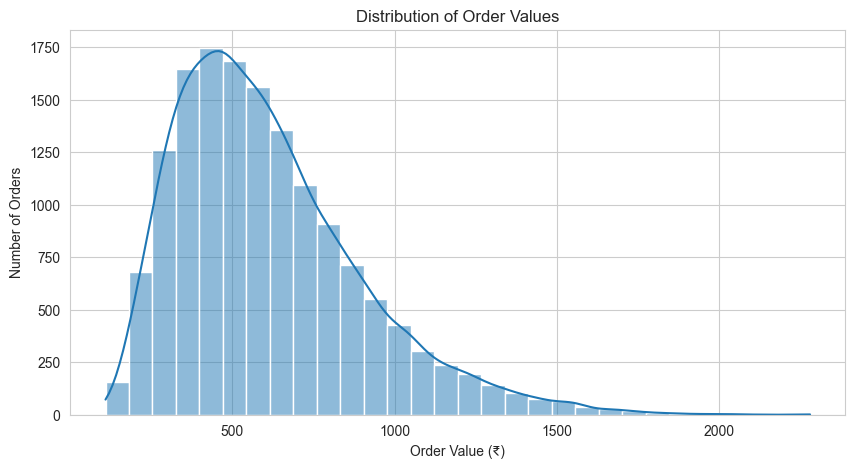

In [35]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Order_Value'], bins=30, kde=True)

plt.title('Distribution of Order Values')
plt.xlabel('Order Value (₹)')
plt.ylabel('Number of Orders')

plt.show()


**Key Insights:**

- The average customer order value is ₹611.92.
- The median order value is ₹558.46, indicating that half of the orders have values below this amount and half are above it.
- The average being higher than the median suggests that relatively high-value orders may be influencing the overall average.
- The standard deviation of ₹287.72 indicates considerable variation in customer spending.
- Order values range from ₹109.48 to ₹2,280.42.

**Business Recommendation:**

Swiggy can explore personalised offers, combo deals and targeted promotions to encourage customers to increase their order value. High-value customer segments can also be studied to understand their purchasing preferences.


### Task 1.2 Popular food categories and restaurants

In [36]:
category_orders = df['Food_Category'].value_counts()

print(category_orders)

Food_Category
North Indian    2402
Biryani         1986
South Indian    1799
Chinese         1788
Pizza           1496
Burgers         1319
Desserts        1210
Street Food     1176
Healthy          943
Continental      881
Name: count, dtype: int64


**Key Insights – Food Category Analysis**

- North Indian is the most popular food category, with 2,402 orders.
- Biryani ranks second with 1,986 orders, followed by South Indian with 1,799 orders.
- Continental is the least popular category, recording 881 orders.
- Customer preferences are concentrated more heavily in North Indian, Biryani and South Indian cuisines.

**Business Recommendation:**

Swiggy can focus on maintaining a strong selection of popular cuisines while using targeted promotions and offers to encourage orders from less popular categories.

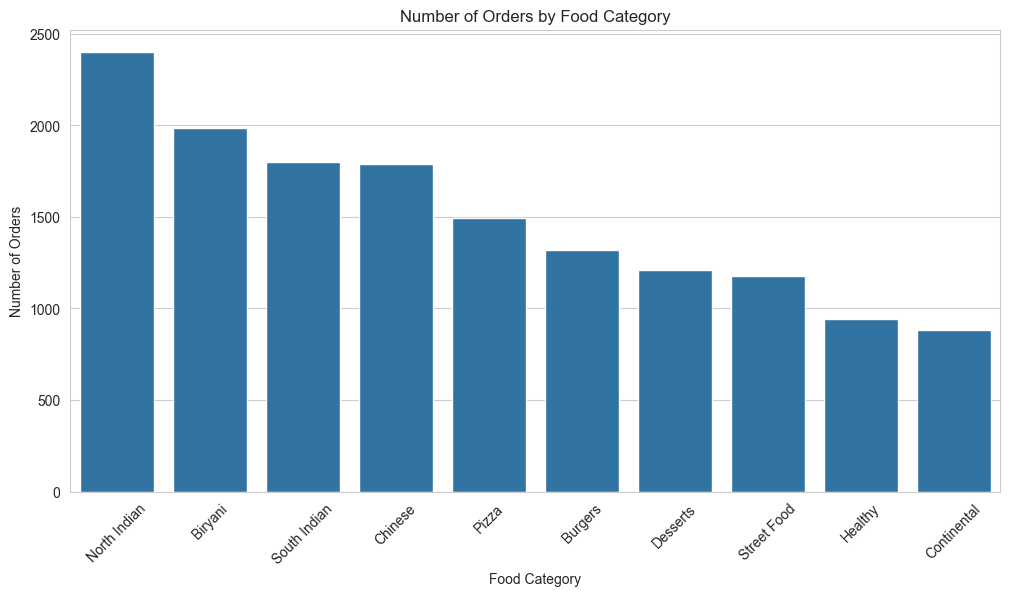

In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_orders.index,
    y=category_orders.values
)

plt.title('Number of Orders by Food Category')
plt.xlabel('Food Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

In [38]:
restaurant_orders = df['Restaurant_Name'].value_counts()

print(restaurant_orders.head(10))

Restaurant_Name
Punjabi Tadka       634
The Curry House     600
Delhi Darbar        591
Shahi Rasoi         577
Dum Biryani         511
Biryani Hub         499
Hyderabadi House    492
Biryani Blues       484
South Spice         481
Madras Cafe         476
Name: count, dtype: int64


**Key Insights – Restaurant Popularity Analysis**

- Punjabi Tadka is the most popular restaurant, recording 634 orders.
- The Curry House ranks second with 600 orders.
- Delhi Darbar ranks third with 591 orders.
- Madras Cafe recorded 476 orders among the top 10 restaurants.
- The results indicate that a few restaurants attract a relatively higher number of customer orders.

**Business Recommendation:**

Swiggy can maintain strong partnerships with popular restaurants and explore promotional campaigns with other restaurants to improve their visibility and increase order volume.

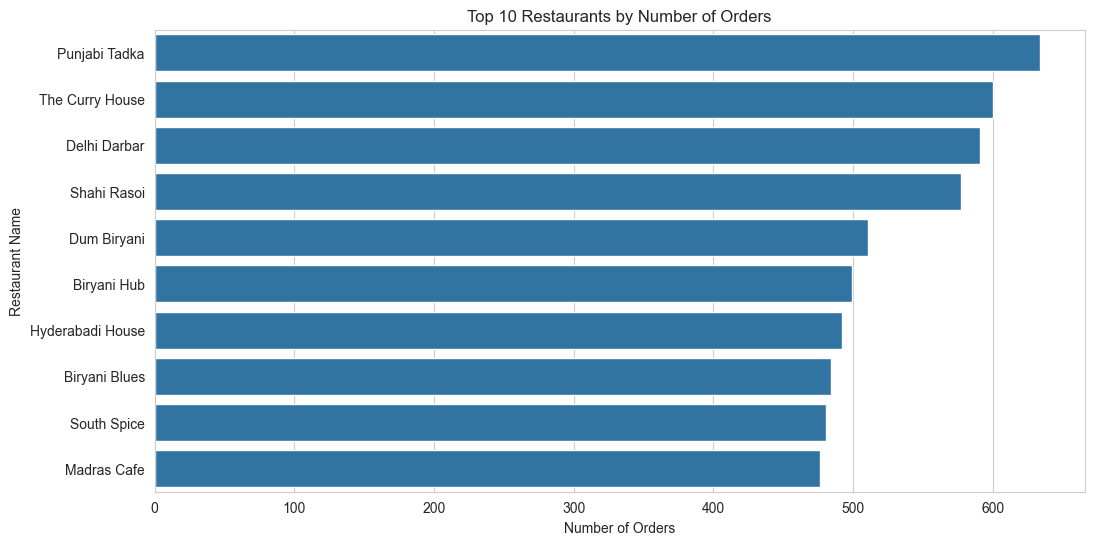

In [39]:
plt.figure(figsize=(12, 6))

top_restaurants = restaurant_orders.head(10)

sns.barplot(
    x=top_restaurants.values,
    y=top_restaurants.index
)

plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')

plt.show()

### Task 1.3 Identify the cities receiving the highest number of orders

In [40]:
city_orders = df['City'].value_counts()

print(city_orders)

City
Hyderabad    1574
Lucknow      1520
Mumbai       1515
Pune         1512
Ahmedabad    1509
Jaipur       1481
Delhi        1478
Kolkata      1478
Bengaluru    1471
Chennai      1462
Name: count, dtype: int64


**Key Insights – City-wise Order Analysis**

- Hyderabad recorded the highest number of orders, with 1,574.
- Lucknow ranked second with 1,520 orders.
- Mumbai ranked third with 1,515 orders.
- Chennai recorded the lowest number of orders, with 1,462.
- The distribution of orders across the 10 cities is relatively balanced, indicating that order demand is spread across different locations.

**Business Recommendation:**

Swiggy can maintain consistent service availability across all cities while exploring opportunities to increase customer engagement in cities with comparatively lower order volumes.

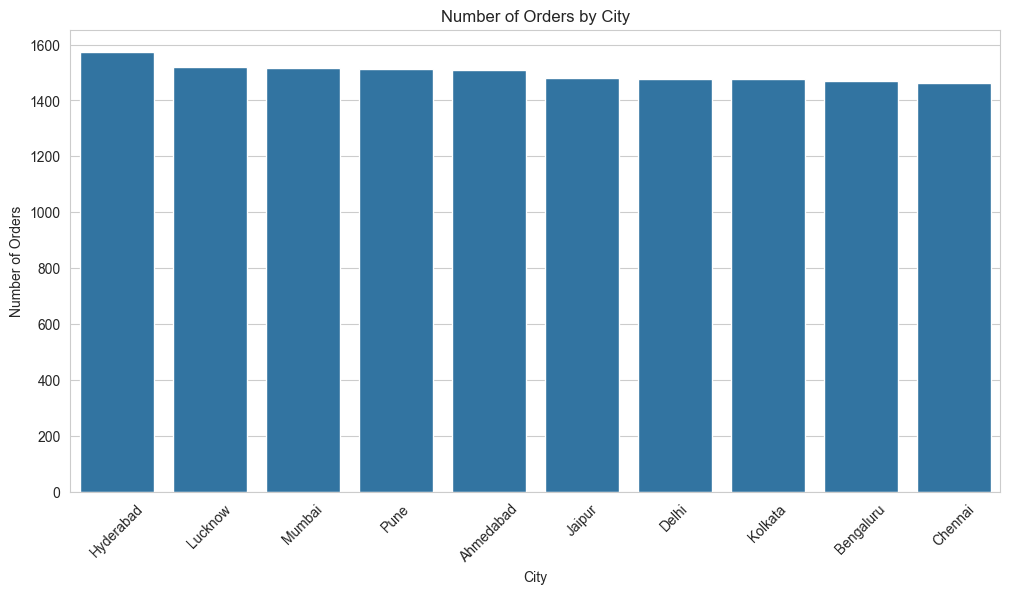

In [41]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_orders.index,
    y=city_orders.values
)

plt.title('Number of Orders by City')
plt.xlabel('City')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

### Task 1.4 Understand customer ratings, payment preferences and order status

In [42]:
print("Average Rating:", df['Rating'].mean())
print("Median Rating:", df['Rating'].median())
print("Highest Rating:", df['Rating'].max())
print("Lowest Rating:", df['Rating'].min())

print("\nRating Distribution:")
print(df['Rating'].value_counts().sort_index())

Average Rating: 3.9857400000000003
Median Rating: 4.0
Highest Rating: 5.0
Lowest Rating: 1.7

Rating Distribution:
Rating
1.7       1
1.8       1
2.2       1
2.3       6
2.4       7
2.5      16
2.6      18
2.7      46
2.8      77
2.9     102
3.0     167
3.1     203
3.2     313
3.3     438
3.4     584
3.5     682
3.6     869
3.7    1046
3.8    1194
3.9    1253
4.0    1215
4.1    1230
4.2    1128
4.3     984
4.4     877
4.5     714
4.6     548
4.7     437
4.8     290
4.9     203
5.0     350
Name: count, dtype: int64


**Key Insights – Customer Rating Analysis**

- The average customer rating is approximately 3.99 out of 5.
- The median rating is 4.0, indicating that the typical customer rating is around 4.
- The highest recorded rating is 5.0, while the lowest is 1.7.
- The most frequently given rating is 3.9, with 1,253 occurrences.
- Most customer ratings fall between 3.5 and 4.5, indicating generally positive customer satisfaction.

**Business Recommendation:**

Swiggy should maintain its service quality while investigating lower-rated orders to identify potential issues related to food quality, restaurant service or delivery experience.

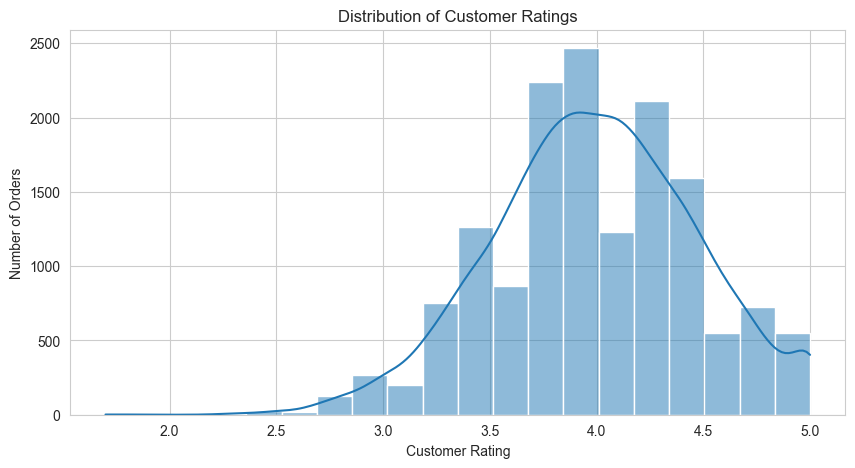

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Rating'],
    bins=20,
    kde=True
)

plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Orders')

plt.show()

In [44]:
payment_counts = df['Payment_Method'].value_counts()

print(payment_counts)

Payment_Method
UPI            6276
Credit Card    3306
Debit Card     2453
Cash           1807
Wallet         1158
Name: count, dtype: int64


**Key Insights – Payment Preference Analysis**

- UPI is the most frequently used payment method, recording 6,276 orders.
- Credit Card ranks second with 3,306 orders.
- Debit Card accounts for 2,453 orders.
- Cash payments account for 1,807 orders.
- Wallet is the least preferred payment method, with 1,158 orders.
- UPI represents approximately 41.84% of all orders, indicating a strong preference for digital payments.

**Business Recommendation:**

Swiggy should continue supporting seamless UPI transactions while maintaining multiple payment options to accommodate different customer preferences.

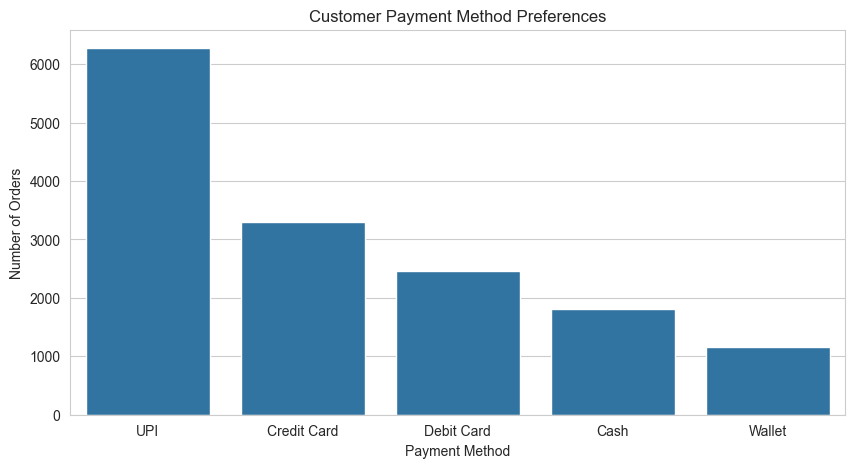

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)

plt.title('Customer Payment Method Preferences')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')

plt.show()

In [46]:
order_status_counts = df['Order_Status'].value_counts()

print(order_status_counts)

Order_Status
Delivered    14083
Cancelled      697
Returned       220
Name: count, dtype: int64


**Key Insights – Order Status Analysis**

- Out of 15,000 total orders, 14,083 were successfully delivered.
- Delivered orders account for approximately 93.89% of all orders.
- 697 orders were cancelled, representing approximately 4.65%.
- 220 orders were returned, representing approximately 1.47%.
- The high delivery success rate indicates that most orders are completed successfully.

**Business Recommendation:**

Swiggy should investigate the reasons behind cancelled and returned orders to identify recurring problems and improve the overall order fulfilment process.

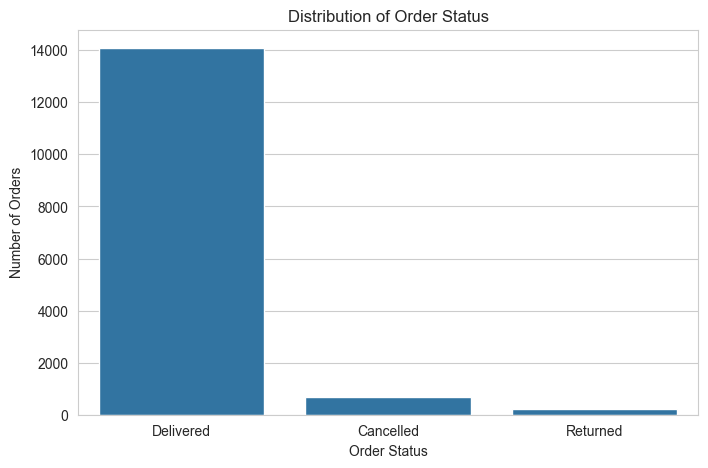

In [47]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Order_Status',
    order=df['Order_Status'].value_counts().index
)

plt.title('Distribution of Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.show()

### Objective 1: Overall Order and Customer Patterns – Summary

The exploratory analysis of 15,000 Swiggy food delivery orders revealed the following findings:

1. **Customer Spending:** The average order value is ₹611.92, while the median is ₹558.46, indicating variation in customer spending.

2. **Food Category Preferences:** North Indian is the most popular food category, recording 2,402 orders, followed by Biryani with 1,986 orders.

3. **Restaurant Popularity:** Punjabi Tadka is the most popular restaurant among the top 10, with 634 orders.

4. **City-wise Orders:** Hyderabad recorded the highest number of orders (1,574), while Chennai recorded the lowest (1,462).

5. **Customer Ratings:** The average customer rating is approximately 3.99 out of 5, indicating generally positive customer feedback.

6. **Payment Preferences:** UPI is the most frequently used payment method, accounting for 6,276 orders (41.84%).

7. **Order Status:** Out of 15,000 orders, 14,083 (93.89%) were successfully delivered, 697 (4.65%) were cancelled and 220 (1.47%) were returned.

**Overall Conclusion:**

The analysis indicates that customer demand is relatively balanced across cities, with clear preferences for certain food categories, restaurants and payment methods. The high delivery success rate and average customer rating suggest generally positive performance, while cancellations and returns present opportunities for improvement.

### Task 2.1 Do higher-value orders take more time to deliver?

In [48]:
correlation = df['Order_Value'].corr(df['Delivery_Time'])

print("Correlation between Order Value and Delivery Time:", correlation)

Correlation between Order Value and Delivery Time: 0.001066125249118655


**Key Insights – Order Value vs Delivery Time**

- The correlation coefficient between order value and delivery time is approximately 0.0011.
- This value is extremely close to zero, indicating almost no linear relationship between the two variables.
- Higher-value orders do not necessarily require longer delivery times.
- Order value alone does not appear to be a useful indicator of delivery duration.

**Business Recommendation:**

Swiggy should investigate other factors, such as delivery distance, restaurant preparation time and traffic conditions, to better understand variations in delivery time.

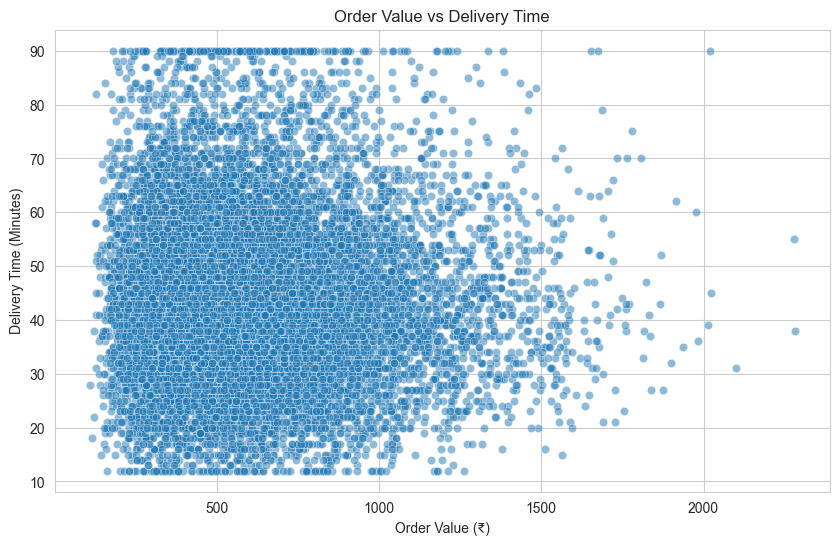

In [49]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Order_Value',
    y='Delivery_Time',
    alpha=0.5
)

plt.title('Order Value vs Delivery Time')
plt.xlabel('Order Value (₹)')
plt.ylabel('Delivery Time (Minutes)')

plt.show()

### Task 2.2 Compare average order value across citie

In [50]:
city_avg_order = df.groupby('City')['Order_Value'].mean().sort_values(ascending=False)

print(city_avg_order)

City
Chennai      618.698256
Pune         616.951085
Lucknow      615.815586
Ahmedabad    614.723903
Delhi        613.599533
Bengaluru    612.414242
Hyderabad    610.603005
Jaipur       609.887623
Kolkata      607.950805
Mumbai       598.785386
Name: Order_Value, dtype: float64


**Key Insights – Average Order Value by City**

- Chennai recorded the highest average order value at approximately ₹618.70.
- Pune ranked second with an average order value of ₹616.95.
- Lucknow ranked third with an average order value of ₹615.82.
- Mumbai recorded the lowest average order value at approximately ₹598.79.
- The difference between the highest and lowest city averages is relatively small, indicating similar spending patterns across cities.

**Business Recommendation:**

Swiggy can explore city-specific promotions and targeted offers to encourage higher customer spending, particularly in cities with comparatively lower average order values.

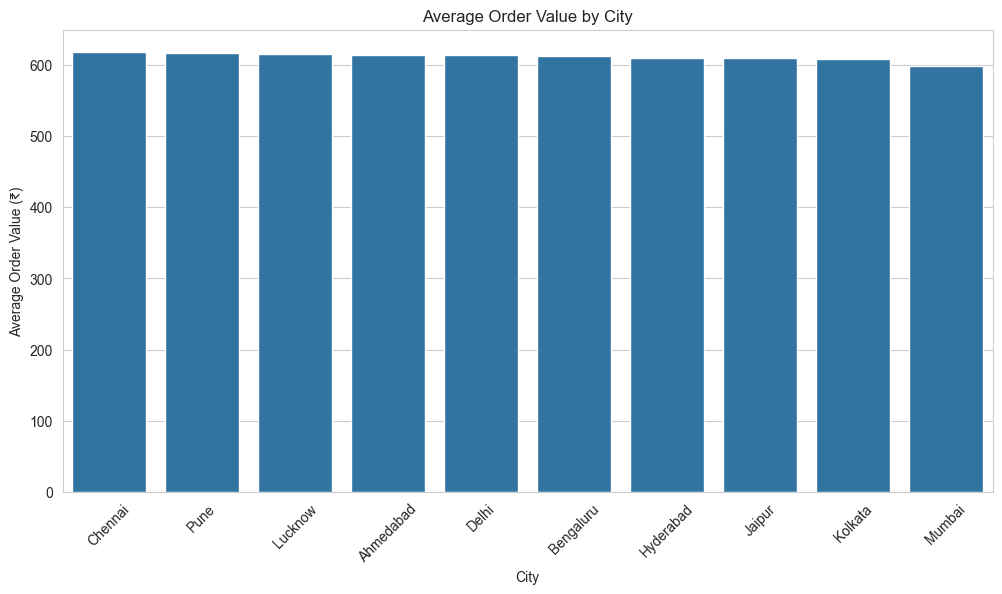

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_avg_order.index,
    y=city_avg_order.values
)

plt.title('Average Order Value by City')
plt.xlabel('City')
plt.ylabel('Average Order Value (₹)')
plt.xticks(rotation=45)

plt.show()

### Task 2.3 correlation between delivery time and customer ratings.

In [52]:
rating_correlation = df['Delivery_Time'].corr(df['Rating'])

print("Correlation between Delivery Time and Rating:", rating_correlation)

Correlation between Delivery Time and Rating: -0.38946111352407226


**Key Insights – Delivery Time vs Customer Satisfaction**

- The correlation coefficient between delivery time and customer ratings is approximately -0.3895.
- This indicates a moderate negative relationship between the two variables.
- Longer delivery times tend to be associated with lower customer ratings.
- Delivery speed may be an important factor influencing customer satisfaction.

**Business Recommendation:**

Swiggy should focus on reducing delivery delays by improving delivery partner allocation, optimising delivery routes and monitoring restaurant preparation times. This may help improve customer satisfaction.

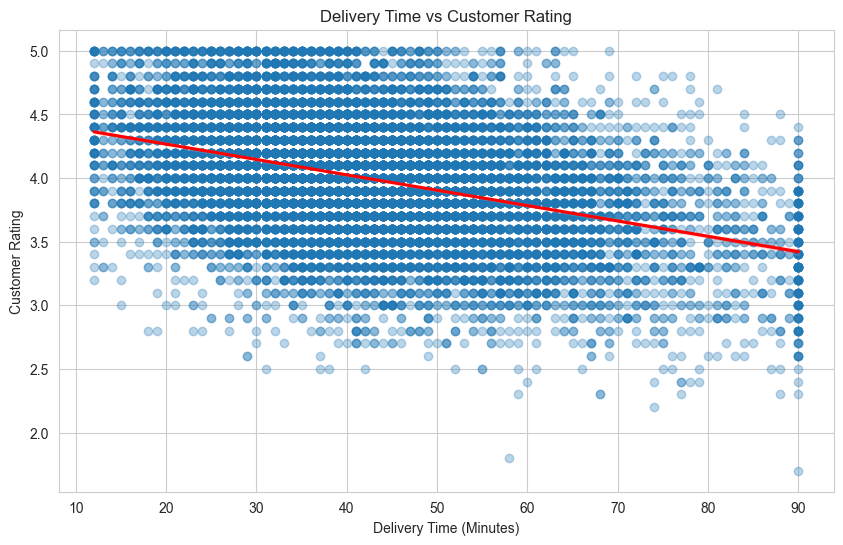

In [53]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Delivery_Time',
    y='Rating',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Delivery Time vs Customer Rating')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Customer Rating')

plt.show()

### Task 2.4 Compare customer ratings across food categories

In [54]:
category_avg_rating = df.groupby('Food_Category')['Rating'].mean().sort_values(ascending=False)

print(category_avg_rating)

Food_Category
Street Food     3.995408
Burgers         3.994466
Healthy         3.992683
Chinese         3.992170
Pizza           3.986297
Biryani         3.985196
South Indian    3.982546
North Indian    3.978435
Continental     3.977526
Desserts        3.977355
Name: Rating, dtype: float64


**Key Insights – Average Customer Ratings by Food Category**

- Street Food received the highest average rating of approximately 3.995.
- Burgers ranked second with an average rating of approximately 3.994.
- Healthy food ranked third with an average rating of approximately 3.993.
- Desserts recorded the lowest average rating of approximately 3.977.
- Average ratings across all food categories are close to 4.0, indicating relatively consistent customer satisfaction.

**Business Recommendation:**

Swiggy can maintain the quality of popular food categories while collecting customer feedback to identify opportunities for improvement in categories with comparatively lower ratings.

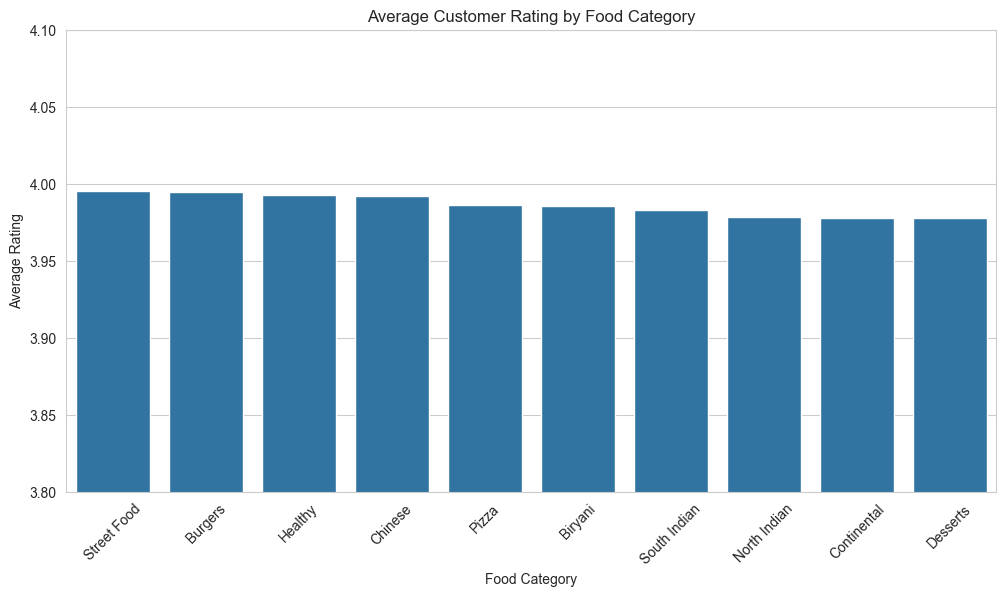

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_avg_rating.index,
    y=category_avg_rating.values
)

plt.title('Average Customer Rating by Food Category')
plt.xlabel('Food Category')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)

plt.ylim(3.8, 4.1)

plt.show()

### Objective 2: Relationships Between Customer Orders and Delivery Performance – Summary

The analysis explored relationships between customer spending, delivery performance and customer satisfaction.

1. **Order Value vs Delivery Time:** The correlation coefficient was approximately 0.0011, indicating virtually no linear relationship between order value and delivery time.

2. **Average Order Value by City:** Chennai recorded the highest average order value at ₹618.70, while Mumbai recorded the lowest at ₹598.79.

3. **Delivery Time vs Customer Satisfaction:** The correlation coefficient was approximately -0.3895, indicating a moderate negative relationship. Longer delivery times tend to be associated with lower customer ratings.

4. **Customer Ratings by Food Category:** Street Food received the highest average rating of approximately 3.995, while Desserts recorded the lowest at approximately 3.977.

**Overall Conclusion:**

The analysis suggests that order value has almost no linear relationship with delivery time, whereas delivery time has a moderate negative relationship with customer ratings. Average spending and customer ratings are relatively consistent across cities and food categories.

**Business Recommendation:**

Swiggy should prioritise improving delivery efficiency, monitoring delayed orders and maintaining consistent service quality to enhance customer satisfaction.

### Objective 3 – Compare Business Performance Across Groups

### Task 3.1 Food categories generating higher order amounts across cities.

In [56]:
category_city_sales = pd.pivot_table(
    df,
    values='Order_Value',
    index='City',
    columns='Food_Category',
    aggfunc='sum'
)

print(category_city_sales)

Food_Category    Biryani   Burgers    Chinese  Continental  Desserts  \
City                                                                   
Ahmedabad      114972.04  86414.60  119282.47     49921.31  72557.96   
Bengaluru      121408.21  69350.10  110672.91     54744.08  77395.29   
Chennai        115485.03  94373.94  115751.70     60541.67  72814.15   
Delhi          128533.93  85676.89   98392.67     60357.17  74713.28   
Hyderabad      135290.78  80348.43  102198.49     55905.10  75885.07   
Jaipur         113320.30  75890.60  104017.28     48120.38  82467.05   
Kolkata        128122.30  77479.59  103039.74     43304.86  72188.18   
Lucknow        127253.70  69234.91  106551.49     49195.86  69410.97   
Mumbai         126339.90  75581.50  107639.32     60390.73  75192.42   
Pune           119264.85  87999.32  114865.99     51991.71  68183.37   

Food_Category   Healthy  North Indian      Pizza  South Indian  Street Food  
City                                                     

**Key Insights – Food Category Performance Across Cities**

- North Indian is the leading food category by total order value in most of the analysed cities.
- Lucknow recorded the highest North Indian order value, at approximately ₹175,665.
- Pune and Ahmedabad also recorded strong North Indian order values of approximately ₹161,715 and ₹160,751 respectively.
- Biryani generated the highest order value among food categories in Delhi, with approximately ₹128,534.
- Food category performance varies across cities, highlighting differences in customer preferences.

**Business Recommendation:**

Swiggy can use city-specific food category preferences to optimise restaurant partnerships, promotional campaigns and menu recommendations. Popular categories in each city can receive greater promotional attention.

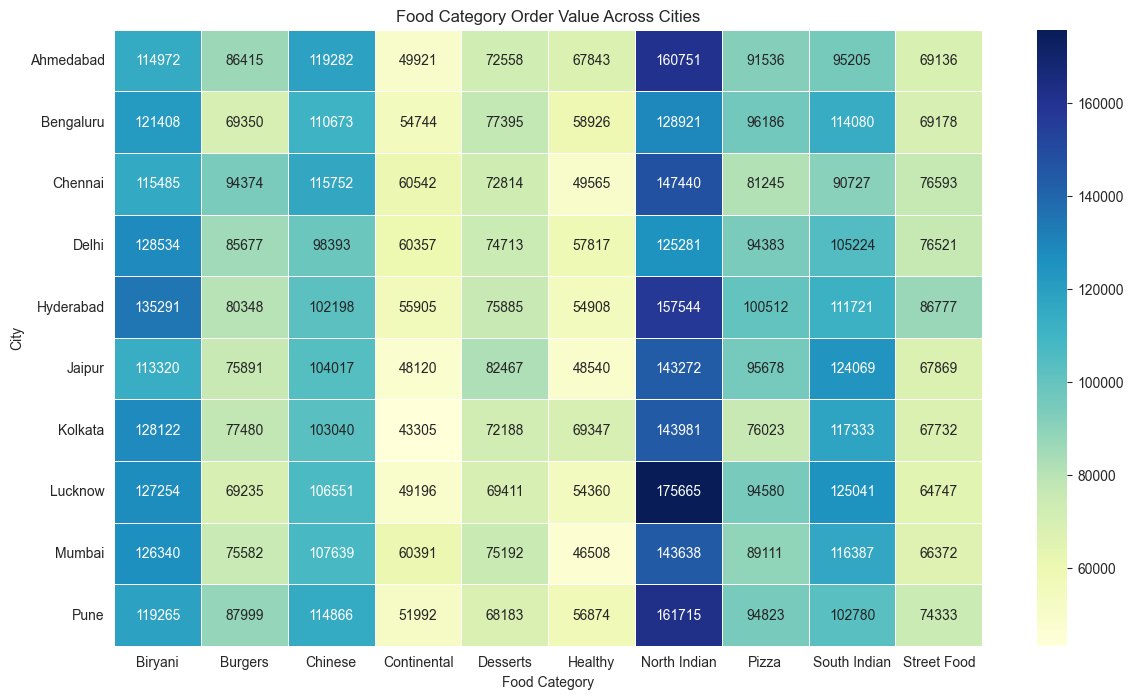

In [57]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    category_city_sales,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Food Category Order Value Across Cities')
plt.xlabel('Food Category')
plt.ylabel('City')

plt.show()

### Task 3.2

In [58]:
city_avg_delivery = df.groupby('City')['Delivery_Time'].mean().sort_values(ascending=False)

print(city_avg_delivery)

City
Lucknow      43.888816
Chennai      43.718194
Kolkata      43.365359
Bengaluru    43.307274
Hyderabad    43.299238
Ahmedabad    43.227966
Pune         43.130952
Delhi        42.823410
Jaipur       42.798109
Mumbai       42.768317
Name: Delivery_Time, dtype: float64


**Insights:**

- Lucknow recorded the highest average delivery time at approximately 43.89 minutes.
- Chennai and Kolkata also had relatively higher average delivery times.
- Mumbai recorded the lowest average delivery time at approximately 42.77 minutes.
- The difference between the highest and lowest city averages is only about 1.12 minutes, indicating fairly consistent delivery times across cities.

**Recommendation:**

The delivery operations team should review delivery processes in cities such as Lucknow and Chennai to identify opportunities to reduce delivery times. However, the differences are small, so major operational changes may not be necessary.

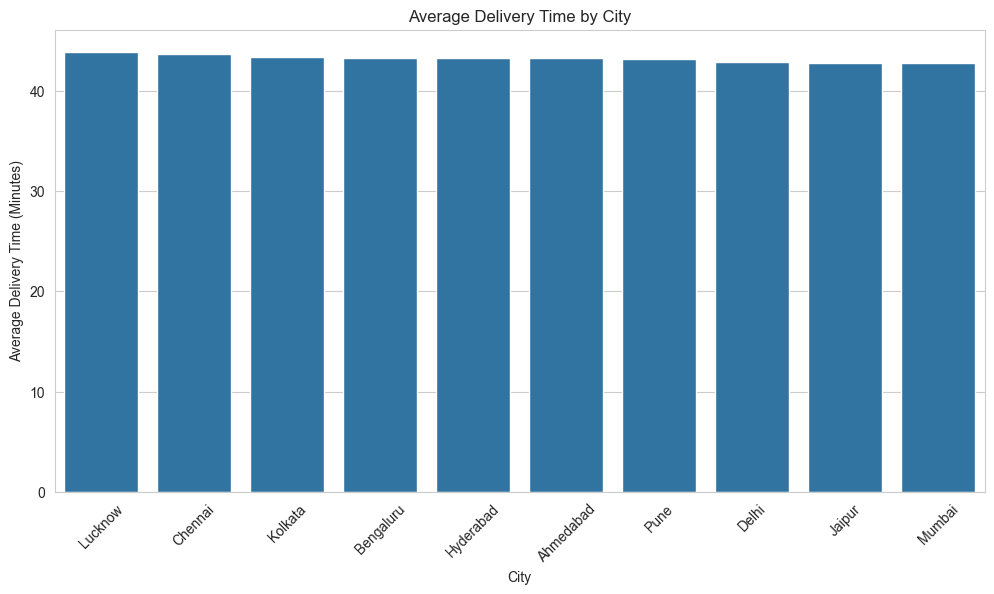

In [59]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_avg_delivery.index,
    y=city_avg_delivery.values
)

plt.title('Average Delivery Time by City')
plt.xlabel('City')
plt.ylabel('Average Delivery Time (Minutes)')
plt.xticks(rotation=45)
plt.show()

### Task 3.3 Compare customer ratings across cities and Food categories

In [60]:
city_avg_rating = df.groupby('City')['Rating'].mean().sort_values(ascending=False)

print(city_avg_rating)

City
Jaipur       4.006415
Pune         3.992593
Ahmedabad    3.991385
Bengaluru    3.990755
Kolkata      3.990460
Chennai      3.987688
Mumbai       3.987195
Hyderabad    3.975413
Delhi        3.975372
Lucknow      3.961184
Name: Rating, dtype: float64


*Insights* – Average Customer Rating by City
- Jaipur has the highest average customer rating at 4.01.
- Pune ranks second with an average rating of 3.99.
- Ahmedabad, Bengaluru and Kolkata also have ratings close to 4.0.
- Lucknow has the lowest average rating at 3.96.
- The ratings across all cities are quite similar, with only a small difference between the highest and lowest averages.
Recommendation: Swiggy should investigate customer feedback in Lucknow to identify possible areas for improvement. Jaipur's performance can also be studied to understand what contributes to better customer experiences.

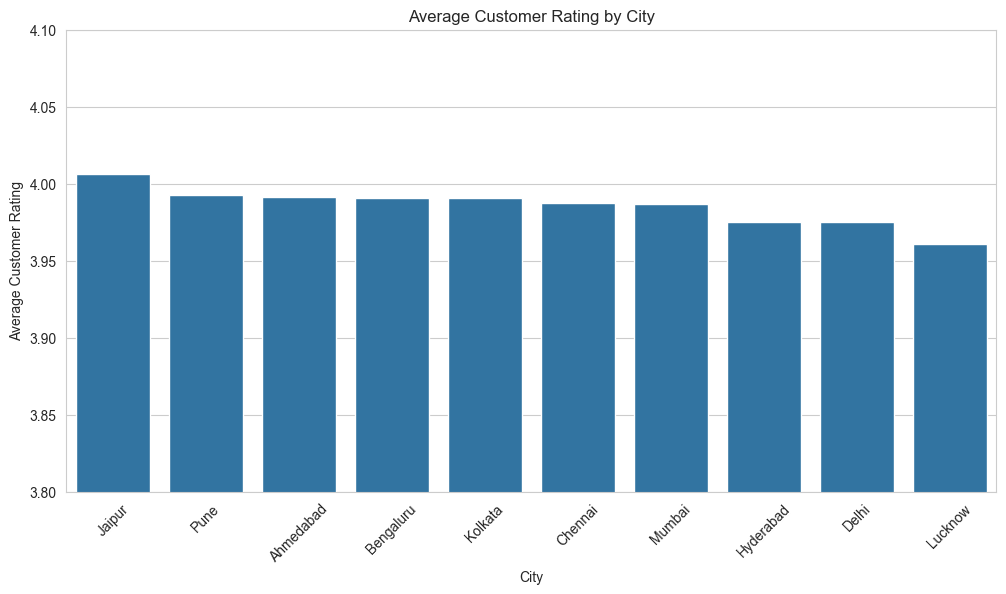

In [61]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_avg_rating.index,
    y=city_avg_rating.values
)

plt.title('Average Customer Rating by City')
plt.xlabel('City')
plt.ylabel('Average Customer Rating')
plt.xticks(rotation=45)
plt.ylim(3.8, 4.1)

plt.show()

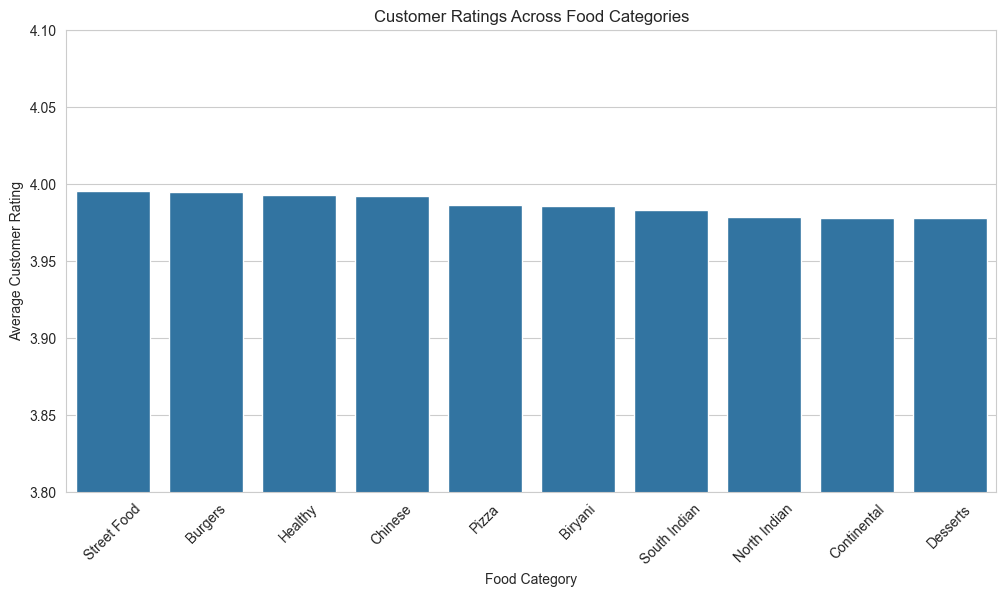

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_avg_rating.index,
    y=category_avg_rating.values
)

plt.title('Customer Ratings Across Food Categories')
plt.xlabel('Food Category')
plt.ylabel('Average Customer Rating')
plt.xticks(rotation=45)
plt.ylim(3.8, 4.1)

plt.show()

### Task 3.4 Identify restaurants and food categories that perform well in different cities

In [63]:
restaurant_city_orders = pd.pivot_table(
    df,
    values='Order_ID',
    index='City',
    columns='Restaurant_Name',
    aggfunc='count',
    fill_value=0
)

print(restaurant_city_orders)

Restaurant_Name  Big Bite  Biryani Blues  Biryani Hub  Burger Junction  \
City                                                                     
Ahmedabad              37             44           58               41   
Bengaluru              24             40           67               29   
Chennai                34             56           38               42   
Delhi                  36             49           37               35   
Hyderabad              36             60           57               30   
Jaipur                 40             42           44               28   
Kolkata                30             45           51               29   
Lucknow                35             47           52               30   
Mumbai                 21             54           50               24   
Pune                   35             47           45               32   

Restaurant_Name  Burger Point  Cafe Bistro  Cake Studio  Chaat Street  \
City                                  

In [64]:
top_restaurants_by_city = restaurant_city_orders.idxmax(axis=1)
top_restaurant_orders = restaurant_city_orders.max(axis=1)

restaurant_city_summary = pd.DataFrame({
    'Top Restaurant': top_restaurants_by_city,
    'Number of Orders': top_restaurant_orders
})

print(restaurant_city_summary)

            Top Restaurant  Number of Orders
City                                        
Ahmedabad    Punjabi Tadka                80
Bengaluru      Biryani Hub                67
Chennai      Punjabi Tadka                63
Delhi          Dum Biryani                71
Hyderabad      Shahi Rasoi                66
Jaipur     The Curry House                65
Kolkata       Delhi Darbar                61
Lucknow        Shahi Rasoi                76
Mumbai       Punjabi Tadka                76
Pune           Shahi Rasoi                65


**Insights** – Top Restaurants by City
Punjabi Tadka leads in three cities: Ahmedabad, Chennai and Mumbai.

Shahi Rasoi leads in Hyderabad, Lucknow and Pune.

Biryani Hub, Dum Biryani, The Curry House and Delhi Darbar lead in one city each.

Ahmedabad has the highest top-restaurant order count (80).

Kolkata has the lowest top-restaurant order count (61).

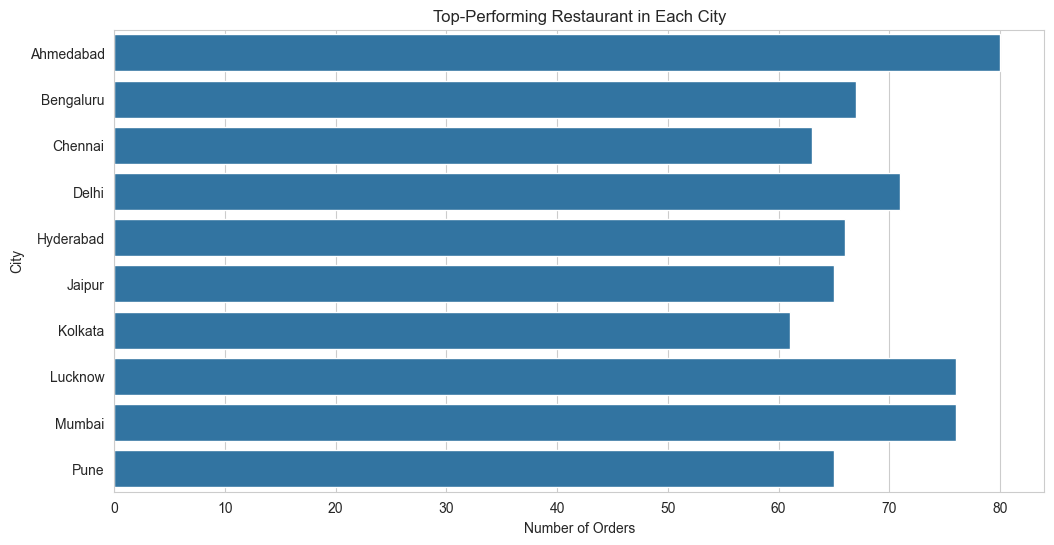

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=restaurant_city_summary,
    x='Number of Orders',
    y=restaurant_city_summary.index
)

plt.title('Top-Performing Restaurant in Each City')
plt.xlabel('Number of Orders')
plt.ylabel('City')

plt.show()

In [66]:
top_category_by_city = category_city_sales.idxmax(axis=1)
top_category_sales = category_city_sales.max(axis=1)

category_city_summary = pd.DataFrame({
    'Top Food Category': top_category_by_city,
    'Total Order Value (₹)': top_category_sales
})

print(category_city_summary)

          Top Food Category  Total Order Value (₹)
City                                              
Ahmedabad      North Indian              160750.61
Bengaluru      North Indian              128920.77
Chennai        North Indian              147440.31
Delhi               Biryani              128533.93
Hyderabad      North Indian              157543.62
Jaipur         North Indian              143272.18
Kolkata        North Indian              143981.43
Lucknow        North Indian              175665.01
Mumbai         North Indian              143637.66
Pune           North Indian              161715.02


**Insights** – Top Food Category by City
North Indian is the leading category in 9 out of 10 cities.

Delhi is the only city where Biryani generates the highest order value.

Lucknow records the highest North Indian order value at ₹175,665.01.

Bengaluru has the lowest North Indian order value among the cities where it leads.

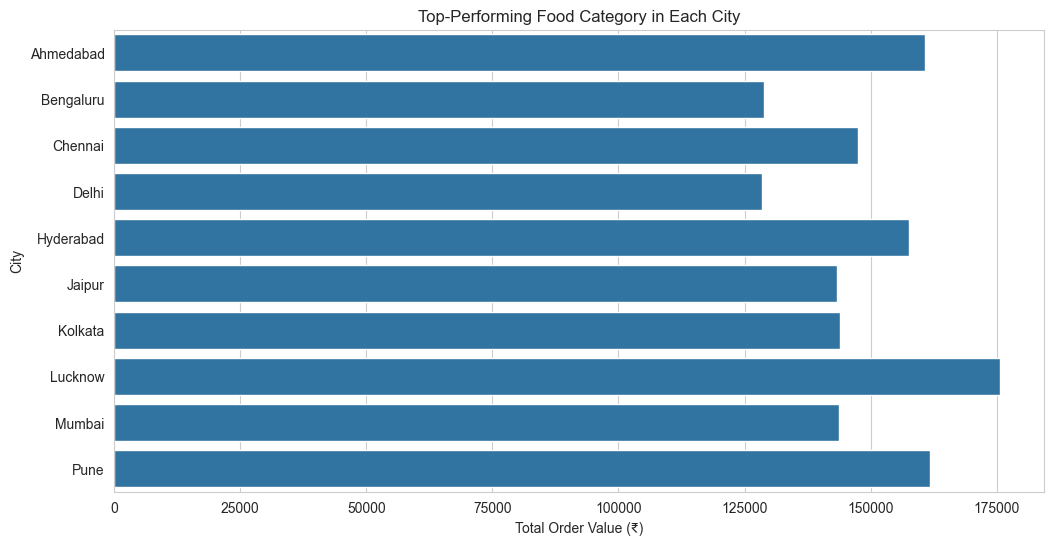

In [67]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_city_summary,
    x='Total Order Value (₹)',
    y=category_city_summary.index
)

plt.title('Top-Performing Food Category in Each City')
plt.xlabel('Total Order Value (₹)')
plt.ylabel('City')

plt.show()

### Objective 3: Business Performance Across Groups

**1. Food Category Performance Across Cities**
- North Indian generated the highest total order value in 9 out of 10 cities.
- Delhi was the exception, where Biryani generated the highest order value.
- Lucknow recorded the highest North Indian order value at ₹175,665.01.

**2. Cities with Longer Delivery Times**
- Lucknow recorded the highest average delivery time at 43.89 minutes.
- Mumbai recorded the lowest at 42.77 minutes.
- Delivery times were relatively consistent across cities.

**3. Customer Ratings Across Cities and Food Categories**
- Jaipur had the highest average city rating at 4.01.
- Lucknow had the lowest at 3.96.
- Street Food received the highest average category rating (3.9954), while Desserts received the lowest (3.9774).
- Ratings were relatively consistent across cities and categories.

**4. Restaurant Performance Across Cities**
- Punjabi Tadka was the leading restaurant in Ahmedabad, Chennai and Mumbai.
- Shahi Rasoi led in Hyderabad, Lucknow and Pune.
- Other leading restaurants included Biryani Hub, Dum Biryani, The Curry House and Delhi Darbar.

**Recommendations:**
- Promote popular food categories according to city-level demand.
- Strengthen restaurant partnerships with high-performing restaurants.
- Investigate delivery operations in cities with longer average delivery times.
- Study customer feedback to identify opportunities to improve satisfaction.

### Objective 4 – Ordering Trends and Recommendations

### Task 4.1 Identify the days when the highest number of orders are placed

In [68]:
df['Day_Name'] = df['Order_Date'].dt.day_name()

daily_orders = df['Day_Name'].value_counts()

# Arrange days in calendar order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_orders = daily_orders.reindex(day_order)

print(daily_orders)

Day_Name
Monday       2164
Tuesday      2207
Wednesday    2170
Thursday     2133
Friday       2080
Saturday     2085
Sunday       2161
Name: count, dtype: int64


Key findings:
- Tuesday is the busiest day, with 2,207 orders.
- Friday has the lowest number of orders, with 2,080.
- Monday, Wednesday and Sunday also show relatively high order volumes.
- Order distribution is fairly balanced throughout the week.
- Recommendation: Swiggy could experiment with targeted promotions on Fridays and Saturdays to encourage more orders, while ensuring sufficient delivery-partner availability on Tuesdays.

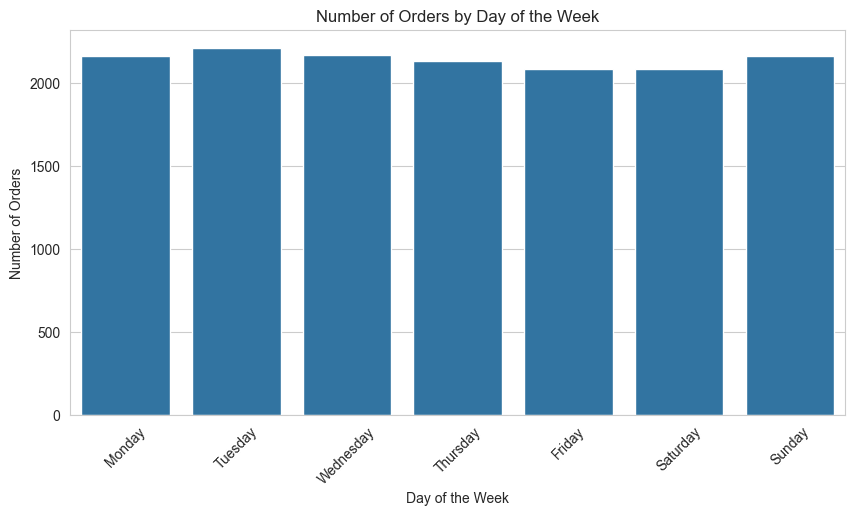

In [69]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_orders.index,
    y=daily_orders.values
)

plt.title('Number of Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

### Task 4.2 Identify the busiest ordering hours

In [70]:
hourly_orders = df['Order_Hour'].value_counts().sort_index()

print(hourly_orders)

Order_Hour
10     412
11     420
12     587
13     648
14     816
15     844
16     935
17    1134
18    1438
19    1690
20    1886
21    1693
22    1456
23    1041
Name: count, dtype: int64


Key findings:
- 8 PM (20:00) is the busiest ordering hour, with 1,886 orders.
- 7 PM (19:00) and 9 PM (21:00) are also very busy.
- Ordering activity increases considerably from 5 PM onwards.
- The period between 6 PM and 10 PM represents the strongest ordering window.
- 10 AM has the lowest order volume among the recorded hours.
Recommendation: Swiggy should ensure sufficient delivery partners, restaurant staff and operational support during evening peak hours, particularly between 7 PM and 9 PM.

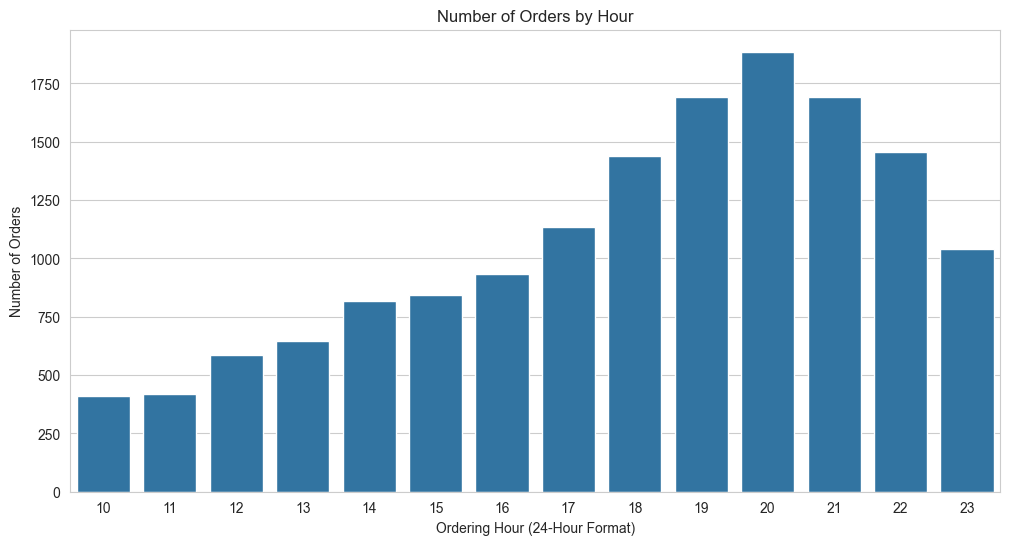

In [71]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=hourly_orders.index,
    y=hourly_orders.values
)

plt.title('Number of Orders by Hour')
plt.xlabel('Ordering Hour (24-Hour Format)')
plt.ylabel('Number of Orders')
plt.xticks(range(14), hourly_orders.index)

plt.show()

### Task 4.3 Identify food categories popular during different time periods

In [72]:
def get_time_period(hour):
    if 6 <= hour <= 11:
        return 'Morning'
    elif 12 <= hour <= 16:
        return 'Afternoon'
    elif 17 <= hour <= 19:
        return 'Evening'
    elif 20 <= hour <= 23:
        return 'Night'
    else:
        return 'Other'

df['Time_Period'] = df['Order_Hour'].apply(get_time_period)

print(df['Time_Period'].value_counts())

Time_Period
Night        6076
Evening      4262
Afternoon    3830
Morning       832
Name: count, dtype: int64


In [73]:
category_time_orders = pd.crosstab(
    df['Time_Period'],
    df['Food_Category']
)

print(category_time_orders)

Food_Category  Biryani  Burgers  Chinese  Continental  Desserts  Healthy  \
Time_Period                                                                
Afternoon          515      337      457          217       330      261   
Evening            600      374      482          260       345      250   
Morning            117       86       98           41        70       53   
Night              754      522      751          363       465      379   

Food_Category  North Indian  Pizza  South Indian  Street Food  
Time_Period                                                    
Afternoon               599    370           455          289  
Evening                 686    413           497          355  
Morning                 131     73            98           65  
Night                   986    640           749          467  


Key findings:
- North Indian is the most popular food category across all four time periods.
- Biryani is consistently among the most popular categories.
- During nighttime, Biryani (754 orders) and Chinese food (751 orders) have almost equal demand.
- Night has the highest overall ordering activity, with 6,076 orders.
- Morning has the lowest activity, with 832 orders.

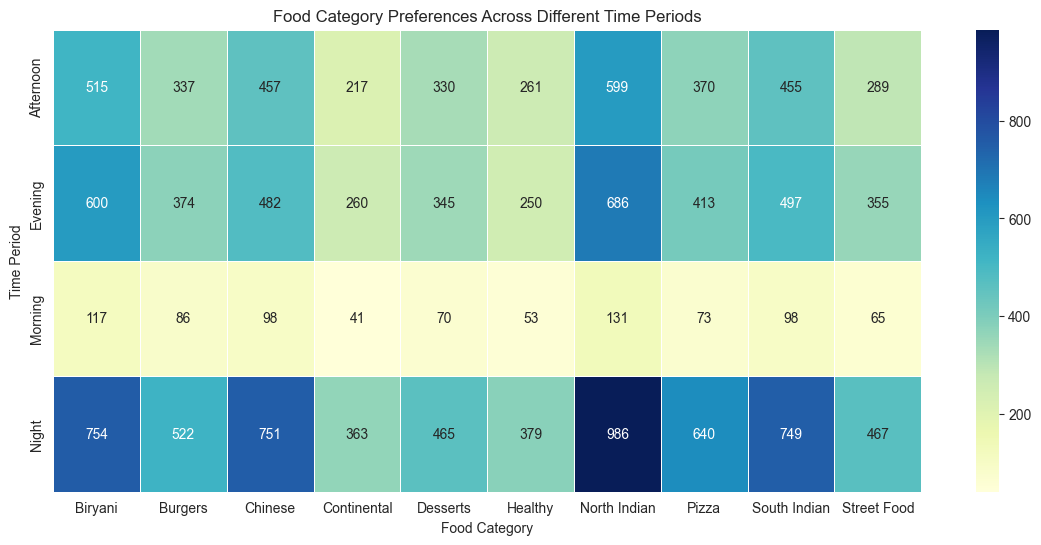

In [74]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    category_time_orders,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Food Category Preferences Across Different Time Periods')
plt.xlabel('Food Category')
plt.ylabel('Time Period')

plt.show()

Recommendation
Swiggy could:
- Increase restaurant and delivery-partner availability during nighttime peak hours.
- Promote North Indian and Biryani options during high-demand periods.
- Offer targeted promotions for afternoon and morning orders.
- Use time-based customer preferences to improve restaurant recommendations.

### Task 4.4 Ordering Trends and Business Recommendations
### 1. Ordering Trends

**Daily Ordering Patterns**
- Tuesday recorded the highest number of orders (2,207).
- Friday recorded the lowest number of orders (2,080).
- Overall ordering activity remained relatively consistent throughout the week.

**Hourly Ordering Patterns**
- 8 PM was the busiest ordering hour, with 1,886 orders.
- Ordering activity increased significantly during the evening.
- The period between 6 PM and 10 PM experienced strong demand.

**Food Category Preferences by Time Period**
- North Indian was the most popular food category across all four time periods.
- Nighttime recorded the highest number of orders (6,076).
- Biryani and Chinese food also showed strong nighttime demand.
- Morning had the lowest number of orders (832), although the dataset only covers 10 AM and 11 AM for this period.

### 2. Recommendations to Improve Delivery Services

- Increase delivery-partner availability during peak hours, particularly between 7 PM and 9 PM.
- Monitor delivery performance in cities such as Lucknow, which recorded the highest average delivery time.
- Improve restaurant preparation and delivery coordination to reduce waiting times.
- Use location-based delivery planning to improve operational efficiency.

### 3. Recommendations to Improve Customer Satisfaction

- Investigate customer feedback in Lucknow, which recorded the lowest average city rating.
- Study customer preferences and maintain the quality of popular food categories.
- Encourage restaurants with lower customer ratings to improve food quality and service.
- Provide accurate delivery estimates and timely order updates.
- Monitor customer complaints, cancellations and returned orders.

### 4. Recommendations for Business Growth

- Strengthen partnerships with popular restaurants such as Punjabi Tadka and Shahi Rasoi.
- Promote North Indian food across cities where it generates the highest order value.
- Focus on Biryani promotions in Delhi, where it is the leading category by order value.
- Introduce targeted offers during less busy periods to encourage additional orders.
- Use customer ordering patterns to provide personalised food recommendations.
- Explore strategies to increase average order value through relevant meal combinations and promotions.

### 5. Overall Conclusion

The analysis of 15,000 Swiggy food delivery records provided insights into customer spending habits, food preferences, restaurant performance, delivery efficiency, customer satisfaction and ordering trends.

The findings indicate that North Indian food is a leading category across most cities, nighttime is the busiest ordering period, and delivery time has a moderate negative relationship with customer ratings.

These insights can help Swiggy improve delivery operations, strengthen restaurant partnerships, enhance customer satisfaction and identify opportunities for sustainable business growth.